# California House Price Prediction: OLS vs. Ridge vs. Lasso
**Goal:** Predict median house values with linear models. This notebook engineers interaction features, imputes missing values, diagnoses and handles multicollinearity, and compares **OLS**, **Ridge (L2)** and **Lasso (L1)** regression on **RMSE, MAE and R²**.

**Pipeline:**
1. Load the data and inspect missing values
2. EDA and correlation heatmap
3. Feature engineering (ratio and interaction features)
4. Train/test split, then preprocessing (median imputation, standardization, one-hot encoding) inside a Scikit-Learn `Pipeline`, so no information leaks from the test set
5. Multicollinearity diagnosis with Variance Inflation Factors (VIF)
6. Fit OLS, and Ridge/Lasso tuned with `GridSearchCV` over many alpha values
7. Benchmark RMSE / MAE / R²
8. Predicted vs. actual plots, residual distributions, and coefficient comparison

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load the dataset

In [3]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

try:
    df = pd.read_csv(URL)
    print("Loaded the dataset from the GitHub URL.")
except Exception as e:
    # Offline fallback: use a local copy of the same file placed next to this notebook
    df = pd.read_csv("housing.csv")
    print("No internet, loaded the local housing.csv instead.")

print("Shape:", df.shape)
df.head()

Loaded the dataset from the GitHub URL.
Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nCategorical column 'ocean_proximity':")
print(df["ocean_proximity"].value_counts())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values per column:
total_bedrooms    207
dtype: int64

Categorical column 'ocean_proximity':
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


**Notes:** Only `total_bedrooms` has missing values. `ocean_proximity` is categorical and must be encoded. The target `median_house_value` is capped at about $500,000 in this dataset, which causes a visible artifact in the residual plots later.

## 2. Exploratory data analysis

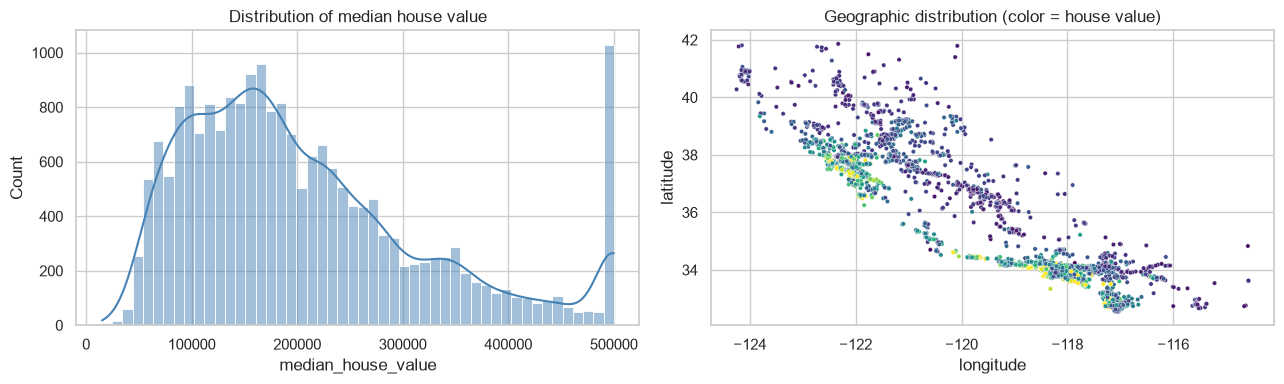

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of median house value")
sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=RANDOM_STATE),
                x="longitude", y="latitude", hue="median_house_value",
                palette="viridis", s=10, ax=axes[1], legend=False)
axes[1].set_title("Geographic distribution (color = house value)")
plt.tight_layout()
plt.show()

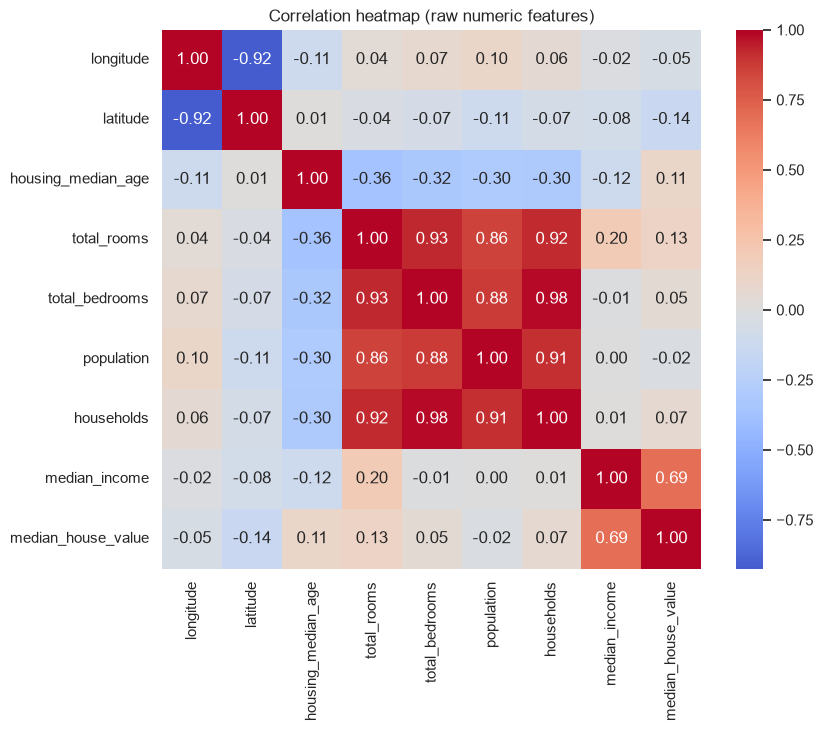

In [6]:
num_cols_raw = df.select_dtypes(include="number").columns
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols_raw].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap (raw numeric features)")
plt.show()

**Observations:** `median_income` has the strongest correlation with the target. `total_rooms`, `total_bedrooms`, `population` and `households` are all highly correlated with each other, a clear sign of **multicollinearity**, which we quantify in section 5.

## 3. Feature engineering
Ratio features describe a typical *household* rather than a whole block. Interaction features let a linear model capture combined effects (for example, income matters more in some places than others).

In [7]:
data = df.copy()

# Ratio features (computed row-wise, so there is no leakage; NaNs are imputed later in the pipeline)
data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
data["population_per_household"] = data["population"] / data["households"]

# Interaction features
data["income_x_rooms_per_hh"] = data["median_income"] * data["rooms_per_household"]
data["income_x_house_age"] = data["median_income"] * data["housing_median_age"]
data["lat_x_lon"] = data["latitude"] * data["longitude"]

engineered = ["rooms_per_household", "bedrooms_per_room", "population_per_household",
              "income_x_rooms_per_hh", "income_x_house_age", "lat_x_lon"]
data[engineered + ["median_house_value"]].corr()["median_house_value"].drop("median_house_value").round(3)

rooms_per_household         0.152
bedrooms_per_room          -0.256
population_per_household   -0.024
income_x_rooms_per_hh       0.555
income_x_house_age          0.589
lat_x_lon                   0.105
Name: median_house_value, dtype: float64

## 4. Train/test split and preprocessing
The target is expressed in units of **$100,000** during training so that regularization strengths (alpha) are on a convenient scale. All metrics are converted back to dollars when reported.

Preprocessing, fitted **only on the training data** inside the pipeline:
- numeric features: median imputation, then `StandardScaler`
- categorical `ocean_proximity`: one-hot encoding, dropping the first level so OLS does not hit the dummy-variable trap

In [8]:
TARGET = "median_house_value"
X = data.drop(columns=TARGET)
y = data[TARGET] / 1e5            # units of $100k

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

cat_features = ["ocean_proximity"]
num_features = [c for c in X.columns if c not in cat_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features),
], sparse_threshold=0)

Train: (16512, 15) | Test: (4128, 15)


## 5. Multicollinearity diagnosis (VIF)
The **Variance Inflation Factor** measures how well each feature can be predicted from all the others. A common rule of thumb: VIF above 5 signals concern, above 10 signals severe multicollinearity. It is computed here from the inverse of the correlation matrix of the (imputed) training features.

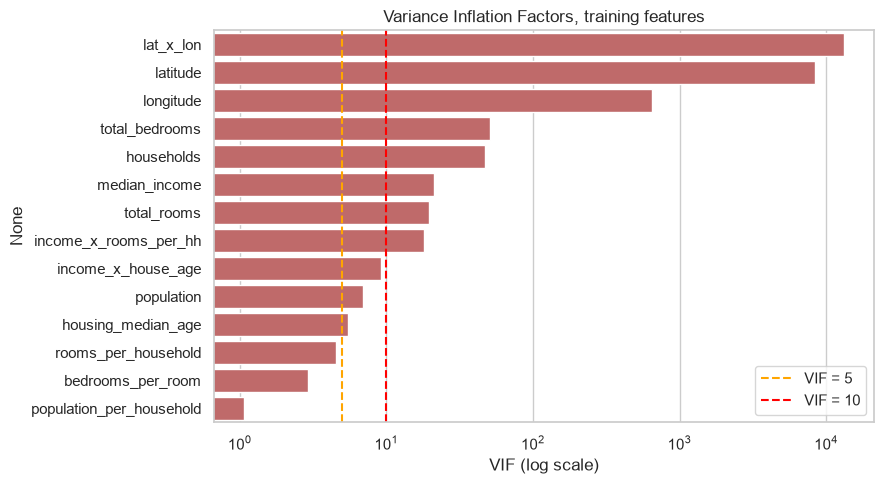

,VIF
lat_x_lon,13243.44
latitude,8339.83
longitude,649.34
total_bedrooms,50.99
households,47.07
median_income,21.06
total_rooms,19.63
income_x_rooms_per_hh,18.00
income_x_house_age,9.19
population,6.91


In [9]:
imputed = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_train[num_features]),
    columns=num_features)
corr_inv = np.linalg.inv(imputed.corr().values)
vif = pd.Series(np.diag(corr_inv), index=num_features, name="VIF").sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=vif.values, y=vif.index, color="indianred")
plt.axvline(5, color="orange", ls="--", label="VIF = 5")
plt.axvline(10, color="red", ls="--", label="VIF = 10")
plt.xscale("log")
plt.xlabel("VIF (log scale)")
plt.title("Variance Inflation Factors, training features")
plt.legend()
plt.tight_layout()
plt.show()
vif.round(2).to_frame()

**Takeaway:** Several features are strongly collinear (the block-level counts, plus the engineered features built from them, and latitude/longitude with their interaction). OLS coefficients become unstable under this condition. **Ridge** shrinks correlated coefficients together, and **Lasso** can drop redundant ones entirely, which is why we compare all three.

## 6. Model training

In [10]:
def make_pipe(model):
    return Pipeline([("prep", preprocessor), ("model", model)])

# --- OLS baseline ---
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

# --- Ridge (L2): GridSearchCV over alpha ---
ridge_grid = GridSearchCV(
    make_pipe(Ridge(random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-3, 3, 13)},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
ridge_grid.fit(X_train, y_train)

# --- Lasso (L1): GridSearchCV over alpha ---
lasso_grid = GridSearchCV(
    make_pipe(Lasso(max_iter=50000, random_state=RANDOM_STATE)),
    param_grid={"model__alpha": np.logspace(-4, 0, 13)},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
lasso_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])

Best Ridge alpha: 0.001
Best Lasso alpha: 0.0001


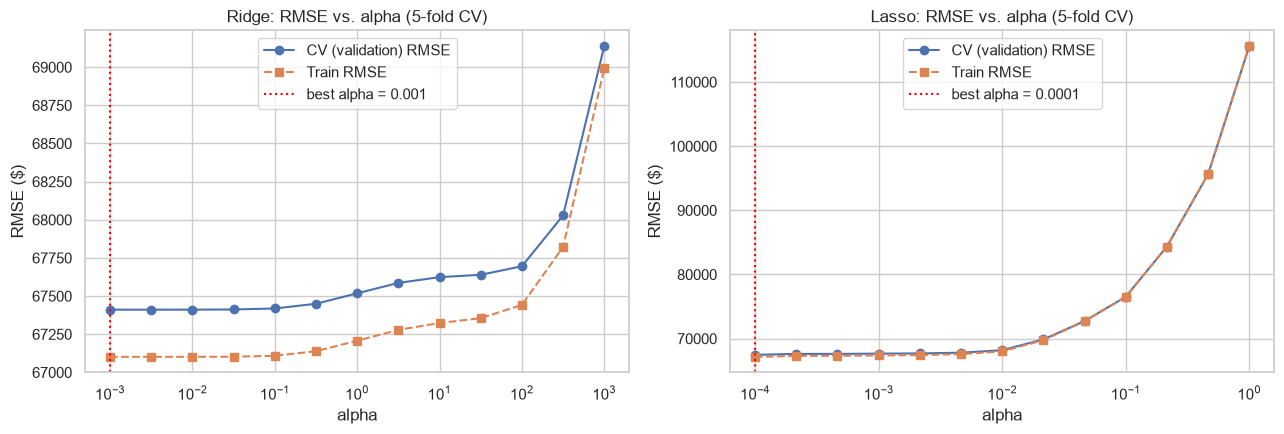

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, grid, name in zip(axes, [ridge_grid, lasso_grid], ["Ridge", "Lasso"]):
    alphas = grid.cv_results_["param_model__alpha"].astype(float)
    ax.semilogx(alphas, -grid.cv_results_["mean_test_score"] * 1e5, "o-", label="CV (validation) RMSE")
    ax.semilogx(alphas, -grid.cv_results_["mean_train_score"] * 1e5, "s--", label="Train RMSE")
    best = grid.best_params_["model__alpha"]
    ax.axvline(best, color="red", ls=":", label=f"best alpha = {best:.4g}")
    ax.set_xlabel("alpha")
    ax.set_ylabel("RMSE ($)")
    ax.set_title(f"{name}: RMSE vs. alpha (5-fold CV)")
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Benchmark: RMSE, MAE and R² on the held-out test set

In [13]:
models = {
    "OLS": ols,
    f"Ridge (alpha={ridge_grid.best_params_['model__alpha']:.3g})": ridge_grid.best_estimator_,
    f"Lasso (alpha={lasso_grid.best_params_['model__alpha']:.3g})": lasso_grid.best_estimator_,
}

preds, rows = {}, []
for name, m in models.items():
    p = m.predict(X_test) * 1e5          # back to dollars
    preds[name] = p
    y_true = y_test.values * 1e5
    rows.append({
        "Model": name,
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, p)),
        "MAE ($)": mean_absolute_error(y_true, p),
        "R2": r2_score(y_true, p),
    })
results = pd.DataFrame(rows).set_index("Model")
results.style.format({"RMSE ($)": "{:,.0f}", "MAE ($)": "{:,.0f}", "R2": "{:.4f}"}) \
       .highlight_min(subset=["RMSE ($)", "MAE ($)"], color="#c6efce") \
       .highlight_max(subset=["R2"], color="#c6efce")

AttributeError: The '.style' accessor requires jinja2

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
results["RMSE ($)"].plot(kind="bar", ax=axes[0], color="steelblue", rot=15)
results["MAE ($)"].plot(kind="bar", ax=axes[1], color="seagreen", rot=15)
results["R2"].plot(kind="bar", ax=axes[2], color="darkorange", rot=15)
for ax, t in zip(axes, ["RMSE ($), lower is better", "MAE ($), lower is better", "R2, higher is better"]):
    ax.set_title(t); ax.set_xlabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3g" if "R2" in t else "%.0f", fontsize=8)
plt.tight_layout()
plt.show()

## 8. Predicted vs. actual

In [ ]:
y_true = y_test.values * 1e5
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [0, max(y_true.max(), max(p.max() for p in preds.values()))]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_true, p, s=6, alpha=0.3, color="steelblue")
    ax.plot(lims, lims, "r--", lw=1.5, label="perfect prediction")
    ax.set_title(f"{name}\nR2 = {r2_score(y_true, p):.3f}")
    ax.set_xlabel("Actual value ($)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted value ($)")
plt.tight_layout()
plt.show()

## 9. Residual analysis

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
for ax, (name, p) in zip(axes, preds.items()):
    resid = y_true - p
    sns.histplot(resid, bins=60, kde=True, ax=ax, color="slateblue")
    ax.axvline(0, color="red", ls="--")
    ax.set_title(f"{name}\nmean={resid.mean():,.0f}, std={resid.std():,.0f}")
    ax.set_xlabel("Residual (actual - predicted, $)")
plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(p, y_true - p, s=6, alpha=0.3, color="teal")
    ax.axhline(0, color="red", ls="--")
    ax.set_title(f"{name}: residuals vs. predicted")
    ax.set_xlabel("Predicted value ($)")
axes[0].set_ylabel("Residual ($)")
plt.tight_layout()
plt.show()

**Reading the residual plots:** Residuals should be centered on zero and roughly symmetric. The diagonal band of points in the residuals-vs-predicted plot comes from the cap on `median_house_value` near $500,000. Funnel shapes would indicate that errors grow with price (heteroscedasticity), a known limitation of plain linear models on this dataset.

## 10. Coefficients: how each model handles multicollinearity

In [ ]:
feature_names = ols.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": ridge_grid.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_grid.best_estimator_.named_steps["model"].coef_,
}, index=[n.split("__")[-1] for n in feature_names])

n_zero = (coefs["Lasso"].abs() < 1e-8).sum()
print(f"Lasso set {n_zero} of {len(coefs)} coefficients to exactly zero:")
print(list(coefs.index[coefs["Lasso"].abs() < 1e-8]))

order = coefs["OLS"].abs().sort_values().index
coefs.loc[order].plot(kind="barh", figsize=(10, 9), width=0.8)
plt.axvline(0, color="k", lw=0.8)
plt.title("Standardized coefficients (target in $100k units)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()
coefs.round(4)

## 11. Summary

In [ ]:
best_rmse = results["RMSE ($)"].idxmin()
best_r2 = results["R2"].idxmax()
print(f"Lowest test RMSE : {best_rmse} (${results['RMSE ($)'].min():,.0f})")
print(f"Lowest test MAE  : {results['MAE ($)'].idxmin()} (${results['MAE ($)'].min():,.0f})")
print(f"Highest test R2  : {best_r2} ({results['R2'].max():.4f})")
print(f"Lasso zeroed out {n_zero} of {len(coefs)} features.")
results.round(4)

## Conclusions
- **Preprocessing:** Imputation, scaling and encoding all live inside the `Pipeline`, so cross-validation and the test evaluation are free of data leakage.
- **Multicollinearity:** The VIF analysis shows strongly collinear features, mostly the block-level counts and the interaction terms built from them. OLS stays unbiased but its coefficients become unstable and hard to interpret.
- **Regularization:** Ridge shrinks collinear coefficients together; Lasso performs feature selection by zeroing some out. With around 20,000 samples and a modest number of features, all three models usually reach similar predictive accuracy, so the main benefit of regularization here is **stability and interpretability** rather than a large accuracy gain. Check the benchmark table above for the exact figures from your run.
- **Limitations:** The $500k cap on the target and non-linear geographic effects limit any linear model.
- **Next steps:** Try `ElasticNet`, polynomial or spatial features (distance to the coast or major cities), a log-transformed target, and tree-based models such as Random Forest or Gradient Boosting as non-linear baselines.